In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lifelines import KaplanMeierFitter
from matplotlib.gridspec import GridSpec
from matplotlib.patheffects import withStroke

In [10]:
# ---
# Load data
# ---

df = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="EIA-860",
)


# ---
# Configuration
# ---

technology_col = "Technology"
capacity_col = "Capacity (MW)"
lifespan_col = "Lifespan"
event_col = "Event"

REFERENCE_LEVELS = [
    0.8,
    0.5,
    0.1,
]


# ---
# Technology groups
# ---

tech_groups = {
    "Fossil fuels": [
        "Coal",
        "Natural Gas",
        "Oil",
    ],
    "Core transition technologies": [
        "Wind Offshore",
        "Wind Onshore",
        "Solar PV",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
    ],
}


# ---
# Prepare data
# ---

df_km = df.copy()

for column in [
    lifespan_col,
    event_col,
    capacity_col,
]:
    df_km[column] = pd.to_numeric(
        df_km[column],
        errors="coerce",
    )

df_km = df_km.dropna(
    subset=[
        technology_col,
        lifespan_col,
        event_col,
    ]
).copy()

# Preserve the original analysis condition
df_km = df_km[
    (df_km[lifespan_col] > 0) &
    (df_km[capacity_col] > 0)
].copy()


# ---
# Style
# ---

FONT_BASE = 12.0
FONT_TICKS = 12.0
FONT_TITLE = 12.5
FONT_PANEL = 12.5
FONT_GROUP_HEADER = 13.0
FONT_REFERENCE_LABEL = 12.0
FONT_INFO = 12.0
FONT_AXIS_LABEL = 13.5

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.75,
        "axes.labelsize": FONT_AXIS_LABEL,
        "axes.titlesize": FONT_TITLE,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TICKS,
        "legend.fontsize": 12.0,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)


KM_COLOUR = "#1D5A7A"               # survival curve
CI_COLOUR = "#DEDBD5"               # 95% confidence band
REFERENCE_COLOUR = "#134257"# "#5E7079"        # 0.8 / 0.5 / 0.1 guide lines (dashed)
REFERENCE_LABEL_COLOUR = "#134257"  # crossing-time readouts
GRID_COLOUR = "#C9C9C9"

TEXT_COLOUR = "#1A1A1A"
SECONDARY_TEXT_COLOUR = "#4A4A4A"
AXIS_COLOUR = "#4A4A4A"
GROUP_LINE_COLOUR = "#8A8A8A"
COLOR_BACKGROUND = "white"

def halo(linewidth=2.4, foreground="white"):
    return [withStroke(linewidth=linewidth, foreground=foreground)]


In [11]:
# ---
# Fit Kaplan-Meier models
# ---

# Fit each technology once and reuse the result for ordering and plotting.
km_models = {}

for tech in df_km[technology_col].dropna().unique():
    subset = df_km[
        df_km[technology_col] == tech
    ]

    if subset.empty:
        continue

    km = KaplanMeierFitter()

    km.fit(
        durations=subset[lifespan_col],
        event_observed=subset[event_col],
    )

    km_models[tech] = km


# ---
# Order technologies
# ---

ordered_groups = {}

for group_name, group_techs in tech_groups.items():
    available_techs = [
        tech
        for tech in group_techs
        if tech in km_models
    ]

    ordered_groups[group_name] = sorted(
        available_techs,
        key=lambda tech: (
            km_models[tech].median_survival_time_
            if pd.notna(
                km_models[tech].median_survival_time_
            )
            else -np.inf
        ),
        reverse=True,
    )


# ---
# Plotting helpers
# ---

# Add a group heading and separator line.
def add_group_header(ax, title):
    ax.axis(
        "off"
    )

    ax.text(
        0.0,
        0.65,
        title,
        transform=ax.transAxes,
        ha="left",
        va="center",
        fontsize=FONT_GROUP_HEADER,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    ax.plot(
        [
            0.0,
            1.0,
        ],
        [
            0.15,
            0.15,
        ],
        transform=ax.transAxes,
        color=GROUP_LINE_COLOUR,
        linewidth=0.75,
        clip_on=False,
    )


# Return GridSpec positions for one technology group.
def get_panel_positions(
    row_indices,
    n_panels,
):
    if n_panels == 3 and len(row_indices) == 1:
        row_index = row_indices[0]

        return [
            (
                row_index,
                slice(0, 4),
            ),
            (
                row_index,
                slice(4, 8),
            ),
            (
                row_index,
                slice(8, 12),
            ),
        ]

    if n_panels == 4 and len(row_indices) == 2:
        top_row, bottom_row = row_indices

        return [
            (
                top_row,
                slice(1, 6),
            ),
            (
                top_row,
                slice(6, 11),
            ),
            (
                bottom_row,
                slice(1, 6),
            ),
            (
                bottom_row,
                slice(6, 11),
            ),
        ]

    raise ValueError(
        "Expected either three panels in one row or four panels in a 2 x 2 layout."
    )


# Plot one technology's Kaplan-Meier survival curve.
def plot_km_panel(
    ax,
    tech,
    panel_label,
):
    subset = df_km[
        df_km[technology_col] == tech
    ].copy()

    if subset.empty or tech not in km_models:
        ax.axis(
            "off"
        )
        return

    km = km_models[tech]

    surv = (
        km.survival_function_
        .reset_index()
    )

    surv.columns = [
        "time",
        "S",
    ]

    surv = surv.sort_values(
        "time"
    )

    ci = (
        km.confidence_interval_
        .reset_index()
    )

    ci.columns = [
        "time",
        "lower",
        "upper",
    ]

    times = surv[
        "time"
    ].to_numpy(
        dtype=float,
    )

    survival = surv[
        "S"
    ].to_numpy(
        dtype=float,
    )

    # 95% confidence interval
    ax.fill_between(
        ci["time"],
        ci["lower"],
        ci["upper"],
        color=CI_COLOUR,
        alpha=0.75,
        step="post",
        linewidth=0,
        zorder=1,
    )

    # Kaplan-Meier curve
    ax.step(
        times,
        survival,
        where="post",
        color=KM_COLOUR,
        linewidth=1.45,
        zorder=4,
    )

    # Reference levels
    for level in REFERENCE_LEVELS:
        crossed = np.where(
            survival <= level
        )[0]

        if len(crossed) == 0:
            continue

        t_level = times[
            crossed[0]
        ]

        is_median = (
            level == 0.5
        )

        line_alpha = (
            0.95
            if is_median
            else 0.60
        )

        line_width = (
            1.00
            if is_median
            else 0.80
        )

        text_alpha = (
            1.00
            if is_median
            else 0.80
        )

        ax.hlines(
            y=level,
            xmin=0,
            xmax=t_level,
            color=REFERENCE_COLOUR,
            linestyle="--",
            linewidth=line_width,
            alpha=line_alpha,
            zorder=2,
        )

        ax.vlines(
            x=t_level,
            ymin=0,
            ymax=level,
            color=REFERENCE_COLOUR,
            linestyle="--",
            linewidth=line_width,
            alpha=line_alpha,
            zorder=2,
        )

        ax.text(
            t_level + 1.5,
            min(
                level + 0.018,
                0.98,
            ),
            f"{t_level:.0f} y",
            ha="left",
            va="bottom",
            fontsize=FONT_REFERENCE_LABEL,
            fontweight=(
                "bold"
                if is_median
                else "normal"
            ),
            color=REFERENCE_COLOUR,
            alpha=text_alpha,
            zorder=5,
        )

    # Number of units and total capacity
    n_units = len(
        subset
    )

    total_capacity_gw = (
        subset[capacity_col].sum()
        / 1000
    )

    if tech == "Hydropower":
        info_y = 0.05
        info_va = "bottom"
    else:
        info_y = 0.95
        info_va = "top"

    ax.text(
        0.97,
        info_y,
        (
            f"n = {n_units:,} | "
            f"{total_capacity_gw:.2f} GW"
        ),
        transform=ax.transAxes,
        ha="right",
        va=info_va,
        fontsize=FONT_INFO,
        fontweight="normal",
        color=SECONDARY_TEXT_COLOUR,
        zorder=6,
    )

    # Panel label
    ax.text(
        -0.13,
        1.12,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_PANEL,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    # Panel title
    ax.set_title(
        tech,
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=6,
        color=TEXT_COLOUR,
    )

    # Axes
    ax.set_xlim(
        0,
        125,
    )

    ax.set_ylim(
        0,
        1.02,
    )

    ax.set_xticks(
        np.arange(
            0,
            126,
            25,
        )
    )

    ax.set_yticks(
        [
            0,
            0.1,
            0.5,
            0.8,
            1.0,
        ]
    )

    # Grid
    ax.grid(
        axis="y",
        linestyle="-",
        linewidth=0.45,
        alpha=0.30,
        color=GRID_COLOUR,
        zorder=0,
    )

    ax.grid(
        axis="x",
        visible=False,
    )

    ax.set_axisbelow(
        True,
    )

    # Spines
    for spine in [
        "top",
        "right",
    ]:
        ax.spines[spine].set_visible(
            False
        )

    for spine in [
        "left",
        "bottom",
    ]:
        ax.spines[spine].set_linewidth(
            0.75
        )
        ax.spines[spine].set_color(
            AXIS_COLOUR
        )

    # Ticks
    ax.tick_params(
        axis="both",
        direction="out",
        length=3.2,
        width=0.75,
        pad=3,
        labelbottom=True,
        labelleft=True,
        labelsize=FONT_TICKS,
        colors=TEXT_COLOUR,
    )


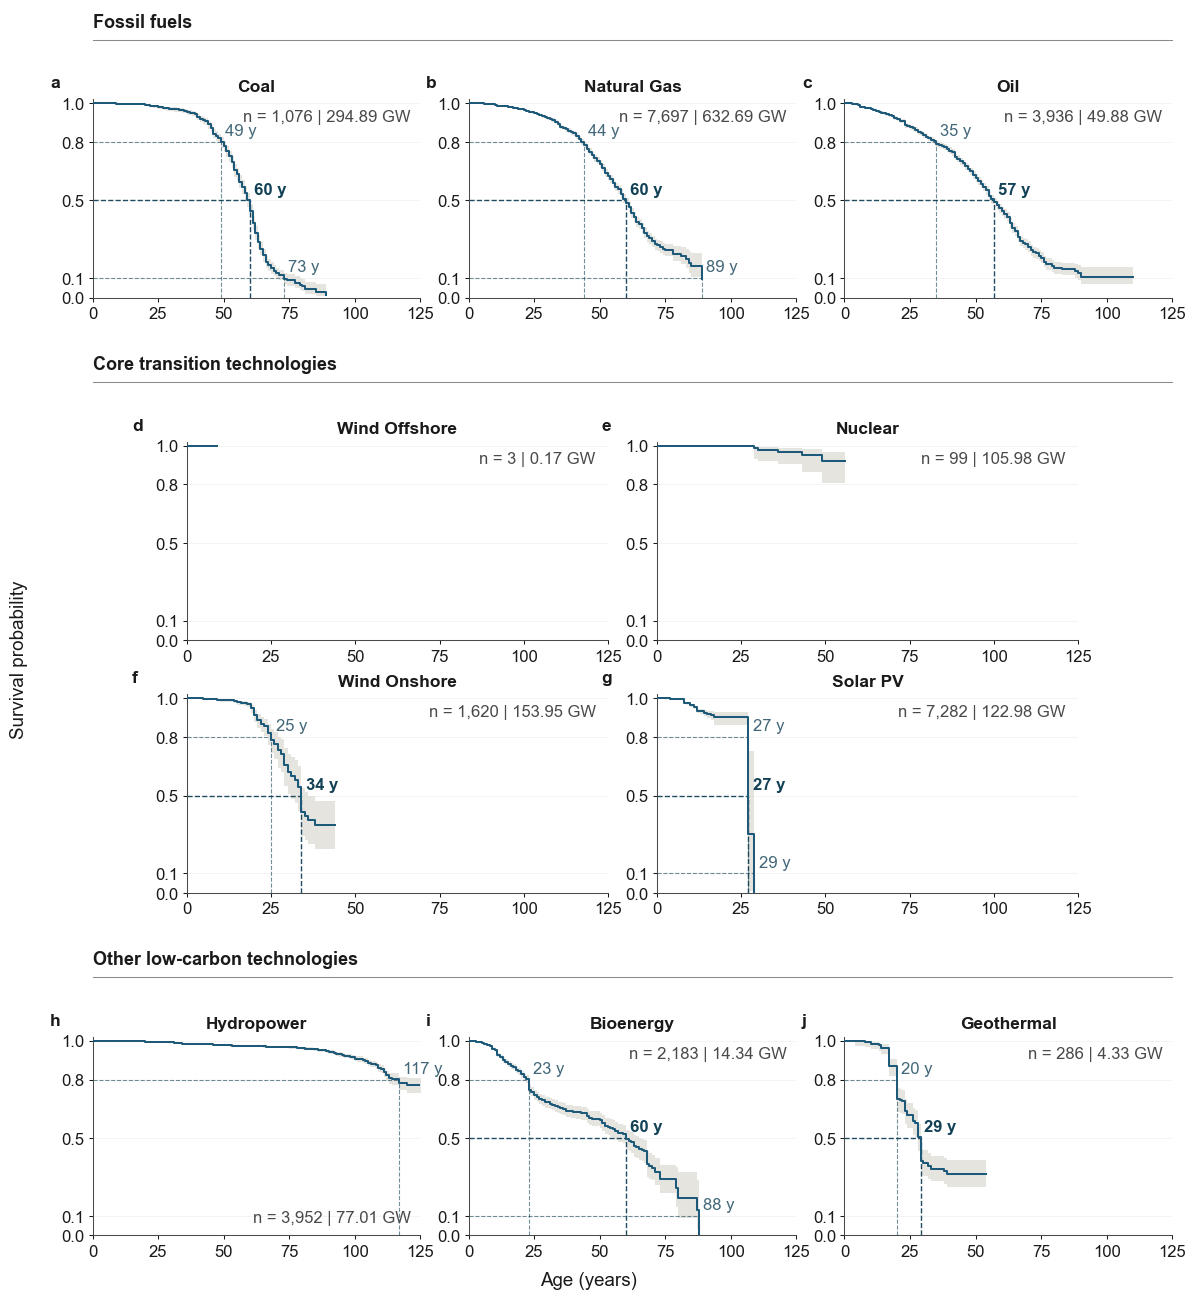

In [12]:
# ---
# Figure
# ---

group_names = list(
    ordered_groups.keys()
)

# Fossil fuels: 1 x 3
# Core transition technologies: 2 x 2
# Other low-carbon technologies: 1 x 3
group_layout = {
    "Fossil fuels": {
        "header_row": 0,
        "panel_rows": [1],
    },
    "Core transition technologies": {
        "header_row": 2,
        "panel_rows": [3, 4],
    },
    "Other low-carbon technologies": {
        "header_row": 5,
        "panel_rows": [6],
    },
}

fig = plt.figure(
    figsize=(
        11.8,
        13.4,
    )
)

gs = GridSpec(
    nrows=7,
    ncols=12,
    figure=fig,
    height_ratios=[
        0.18,
        1.0,
        0.18,
        1.0,
        1.0,
        0.18,
        1.0,
    ],
    hspace=0.42,
    wspace=1.05,
)

fig.patch.set_facecolor(
    COLOR_BACKGROUND
)


# ---
# Group headers
# ---

for group_name in group_names:
    layout = group_layout[
        group_name
    ]

    ax_header = fig.add_subplot(
        gs[
            layout["header_row"],
            :,
        ]
    )

    add_group_header(
        ax_header,
        group_name,
    )


# ---
# Create panels
# ---

share_ax = None
panel_counter = 0

for group_name in group_names:
    tech_list = ordered_groups[
        group_name
    ]

    layout = group_layout[
        group_name
    ]

    positions = get_panel_positions(
        layout["panel_rows"],
        len(tech_list),
    )

    for tech, (
        panel_row,
        col_slice,
    ) in zip(
        tech_list,
        positions,
    ):
        if share_ax is None:
            ax = fig.add_subplot(
                gs[
                    panel_row,
                    col_slice,
                ]
            )

            share_ax = ax
        else:
            ax = fig.add_subplot(
                gs[
                    panel_row,
                    col_slice,
                ],
                sharex=share_ax,
                sharey=share_ax,
            )

        ax.set_facecolor(
            COLOR_BACKGROUND
        )

        plot_km_panel(
            ax=ax,
            tech=tech,
            panel_label=chr(
                97 + panel_counter
            ),
        )

        panel_counter += 1


# ---
# Global labels
# ---

fig.supylabel(
    "Survival probability",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    x=0.010,
    color=TEXT_COLOUR,
)

fig.supxlabel(
    "Age (years)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    y=0.030,
    color=TEXT_COLOUR,
)


# ---
# Layout
# ---

fig.subplots_adjust(
    left=0.080,
    right=0.995,
    bottom=0.070,
    top=0.985,
)


# ---
# Save
# ---

plt.savefig(
    "figures/SI/figure-8.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)
plt.savefig(
    "figures/SI/figure-8.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.show()
